In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, accuracy_score, confusion_matrix, classification_report

In [3]:
df = pd.read_csv('recs2009_public.csv')
df.head()

C:\Users\Dell\AppData\Local\Temp\ipykernel_10520\4242064815.py:1: DtypeWarning: Columns (0: NOCRCASH, 1: NKRGALNC) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('recs2009_public.csv')


,DOEID,REGIONC,DIVISION,REPORTABLE_DOMAIN,TYPEHUQ,NWEIGHT,HDD65,CDD65,HDD30YR,CDD30YR,...,SCALEKER,IECC_Climate_Pub,HDD50,CDD80,GND_HDD65,WSF,OA_LAT,GWT,DesignDBT99,DesignDBT1
0,1,2,4,12,2,2471.68,4742,1080,4953,1271,...,-2,4A,2117,56,4250,0.48,6,56,9,96
1,2,4,10,26,2,8599.17,2662,199,2688,143,...,-2,3C,62,26,2393,0.61,0,64,38,73
2,3,1,1,1,5,8969.92,6233,505,5741,829,...,-2,5A,2346,49,5654,0.48,3,52,12,88
3,4,2,3,7,2,18003.64,6034,672,5781,868,...,-2,5A,2746,0,4941,0.55,4,55,7,87
4,5,1,1,1,3,5999.61,5388,702,5313,797,...,-2,5A,2251,0,5426,0.61,4,50,13,90


In [4]:
df.shape

(12083, 940)

In [5]:
df.columns

Index(['DOEID', 'REGIONC', 'DIVISION', 'REPORTABLE_DOMAIN', 'TYPEHUQ',
       'NWEIGHT', 'HDD65', 'CDD65', 'HDD30YR', 'CDD30YR',
       ...
       'SCALEKER', 'IECC_Climate_Pub', 'HDD50', 'CDD80', 'GND_HDD65', 'WSF',
       'OA_LAT', 'GWT', 'DesignDBT99', 'DesignDBT1'],
      dtype='str', length=940)

In [6]:
df.dtypes

DOEID                  int64
REGIONC                int64
DIVISION               int64
REPORTABLE_DOMAIN      int64
TYPEHUQ                int64
                      ...   
WSF                  float64
OA_LAT                 int64
GWT                    int64
DesignDBT99            int64
DesignDBT1             int64
Length: 940, dtype: object

In [7]:
df.describe()

,DOEID,REGIONC,DIVISION,REPORTABLE_DOMAIN,TYPEHUQ,NWEIGHT,HDD65,CDD65,HDD30YR,CDD30YR,...,PERIODKR,SCALEKER,HDD50,CDD80,GND_HDD65,WSF,OA_LAT,GWT,DesignDBT99,DesignDBT1
count,12083.000000,12083.000000,12083.000000,12083.000000,12083.000000,12083.000000,12083.000000,12083.000000,12083.000000,12083.000000,...,12083.000000,12083.000000,12083.000000,12083.000000,12083.000000,12083.000000,12083.000000,12083.000000,12083.000000,12083.000000
mean,6042.000000,2.628321,5.373086,14.783663,2.659604,9402.981870,4141.375238,1415.406108,4135.146983,1443.503104,...,-1.935943,-1.955392,1681.961764,139.568485,3763.728544,0.499036,5.656046,59.128693,20.256311,90.359431
std,3488.205986,1.042142,2.859366,8.195824,1.192627,5192.101419,2317.759375,1134.659475,2260.543686,1021.748722,...,0.589907,0.415810,1401.079218,264.186908,2597.754419,0.083520,6.797205,8.678293,15.337626,6.166669
min,1.000000,1.000000,1.000000,1.000000,1.000000,476.100000,0.000000,0.000000,0.000000,0.000000,...,-2.000000,-2.000000,0.000000,0.000000,0.000000,0.310000,0.000000,36.000000,-23.000000,60.000000
25%,3021.500000,2.000000,3.000000,8.000000,2.000000,6297.040000,2197.500000,561.000000,2224.000000,712.000000,...,-2.000000,-2.000000,262.500000,4.000000,1246.500000,0.430000,1.000000,52.000000,9.000000,87.000000
50%,6042.000000,3.000000,5.000000,15.000000,2.000000,7970.630000,4483.000000,1045.000000,4502.000000,1179.000000,...,-2.000000,-2.000000,1684.000000,30.000000,3878.000000,0.500000,3.000000,58.000000,18.000000,90.000000
75%,9062.500000,3.000000,7.000000,21.000000,3.000000,11330.030000,5913.000000,1897.000000,5854.000000,1842.500000,...,-2.000000,-2.000000,2662.000000,117.000000,5834.000000,0.560000,7.000000,66.000000,33.000000,94.000000
max,12083.000000,4.000000,10.000000,27.000000,5.000000,95779.140000,12525.000000,5480.000000,13346.000000,5357.000000,...,5.000000,3.000000,7623.000000,1884.000000,11567.000000,0.800000,34.000000,89.000000,67.000000,118.000000


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12083 entries, 0 to 12082
Columns: 940 entries, DOEID to DesignDBT1
dtypes: float64(50), int64(885), object(2), str(3)
memory usage: 86.7+ MB


In [9]:
df.isnull().sum()

DOEID                0
REGIONC              0
DIVISION             0
REPORTABLE_DOMAIN    0
TYPEHUQ              0
                    ..
WSF                  0
OA_LAT               0
GWT                  0
DesignDBT99          0
DesignDBT1           0
Length: 940, dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df = df[df['BEDROOMS'] >= 0]
df.shape

(11868, 940)

In [12]:
q1 = df['TOTALBTU'].quantile(0.25)
q3 = df['TOTALBTU'].quantile(0.75)
IQR = q3 - q1
print("IQR Value is ", IQR)
lb = q1 - 1.5 * IQR
ub = q3 + 1.5 * IQR
print("LB Value is ", lb)
print("UB Value is ", ub)
outliers = ((df['TOTALBTU'] < lb) | (df['TOTALBTU'] > ub)).sum()
print("Outliers Found in column:", outliers)

IQR Value is  65484.5
LB Value is  -45729.25
UB Value is  216208.75
Outliers Found in column: 302


In [13]:
q1_sqft = df['TOTSQFT_EN'].quantile(0.25)
q3_sqft = df['TOTSQFT_EN'].quantile(0.75)
IQR_sqft = q3_sqft - q1_sqft
print("IQR Value is ", IQR_sqft)
lb_sqft = q1_sqft - 1.5 * IQR_sqft
ub_sqft = q3_sqft + 1.5 * IQR_sqft
print("LB Value is ", lb_sqft)
print("UB Value is ", ub_sqft)
outliers_sqft = ((df['TOTSQFT_EN'] < lb_sqft) | (df['TOTSQFT_EN'] > ub_sqft)).sum()
print("Outliers Found in column:", outliers_sqft)

IQR Value is  1544.0
LB Value is  -1235.0
UB Value is  4941.0
Outliers Found in column: 441


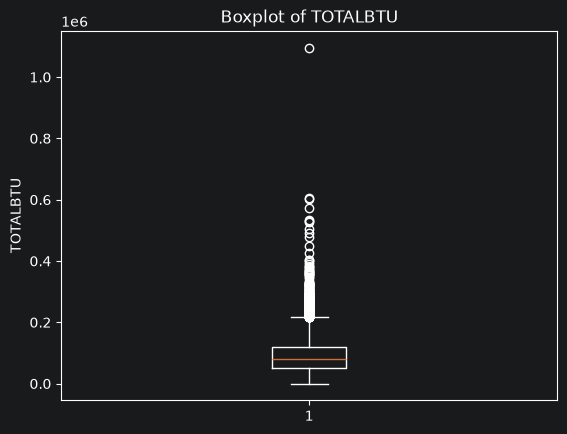

In [14]:
plt.boxplot(df['TOTALBTU'])
plt.title("Boxplot of TOTALBTU")
plt.ylabel("TOTALBTU")
plt.show()

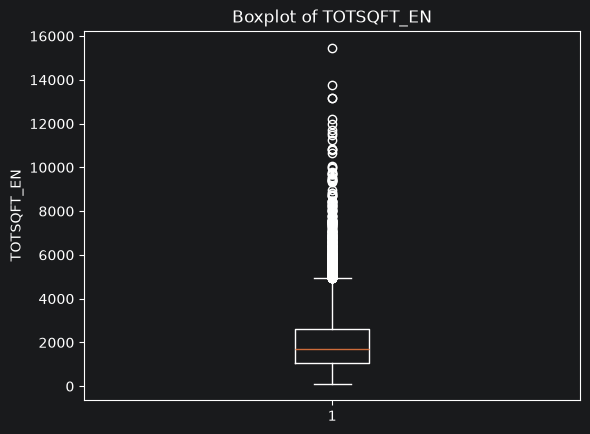

In [15]:
plt.boxplot(df['TOTSQFT_EN'])
plt.title("Boxplot of TOTSQFT_EN")
plt.ylabel("TOTSQFT_EN")
plt.show()

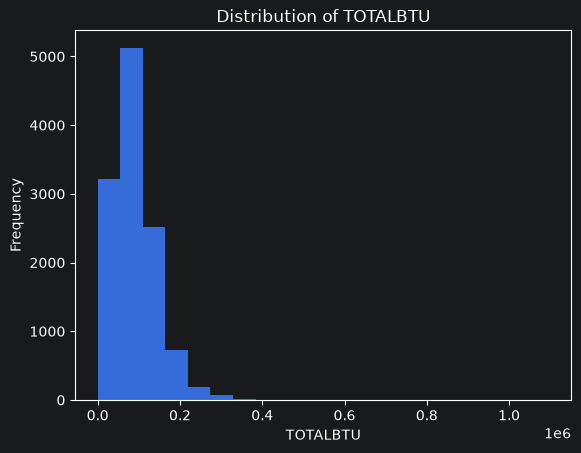

In [16]:
plt.hist(df['TOTALBTU'], bins=20)
plt.title("Distribution of TOTALBTU")
plt.xlabel("TOTALBTU")
plt.ylabel("Frequency")
plt.show()

In [17]:
df['AIRCOND'].value_counts()

AIRCOND
1    9798
0    2070
Name: count, dtype: int64

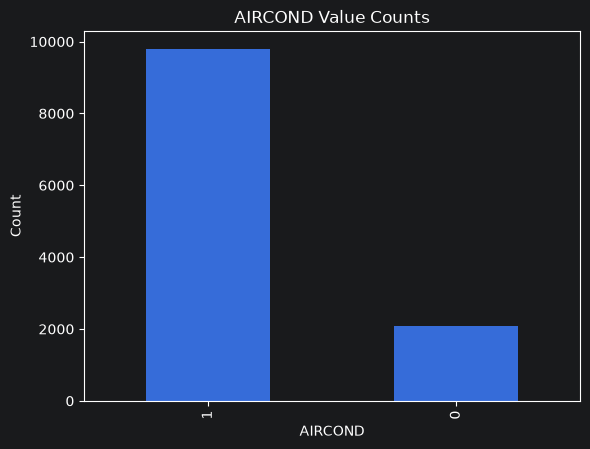

In [18]:
df['AIRCOND'].value_counts().plot(kind='bar')
plt.title("AIRCOND Value Counts")
plt.xlabel("AIRCOND")
plt.ylabel("Count")
plt.show()

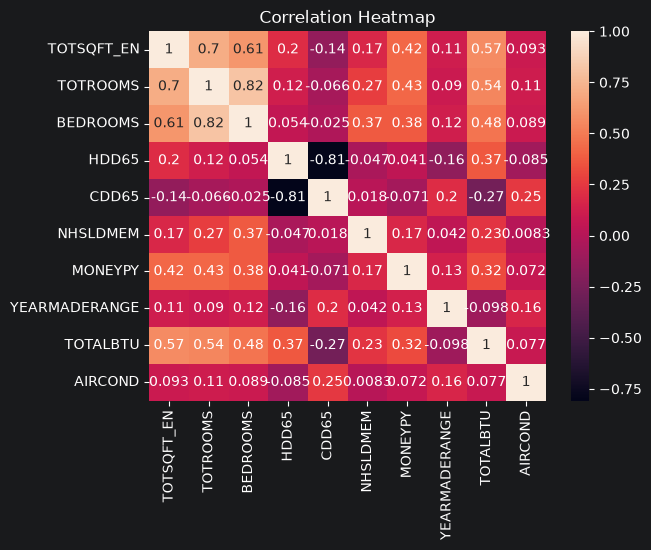

In [19]:
sns.heatmap(df[['TOTSQFT_EN', 'TOTROOMS', 'BEDROOMS', 'HDD65', 'CDD65', 'NHSLDMEM', 'MONEYPY', 'YEARMADERANGE', 'TOTALBTU', 'AIRCOND']].corr(), annot=True)
plt.title("Correlation Heatmap")
plt.show()

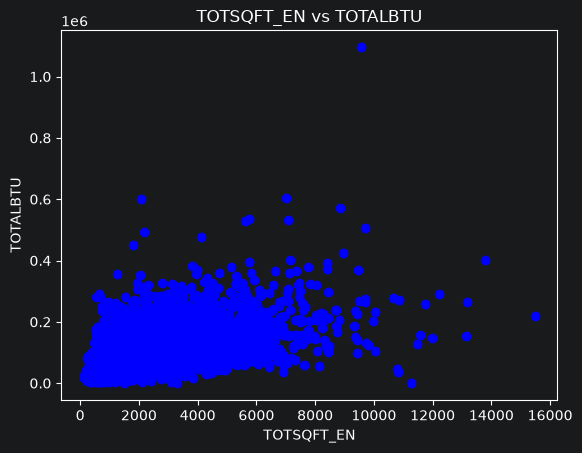

In [20]:
plt.scatter(df['TOTSQFT_EN'], df['TOTALBTU'], color='blue')
plt.title("TOTSQFT_EN vs TOTALBTU")
plt.xlabel("TOTSQFT_EN")
plt.ylabel("TOTALBTU")
plt.show()

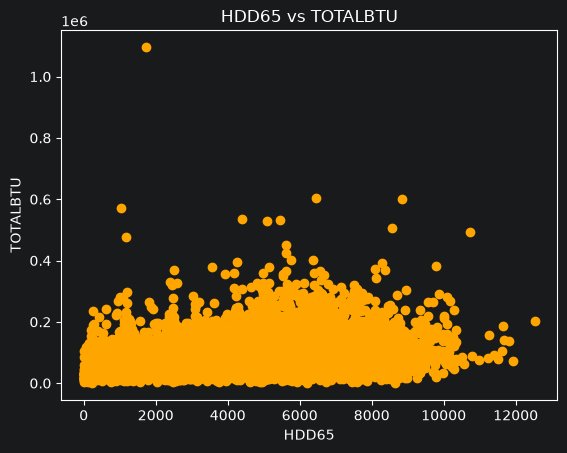

In [21]:
plt.scatter(df['HDD65'], df['TOTALBTU'], color='orange')
plt.title("HDD65 vs TOTALBTU")
plt.xlabel("HDD65")
plt.ylabel("TOTALBTU")
plt.show()

In [22]:
x = df[['TOTSQFT_EN', 'TOTROOMS', 'BEDROOMS', 'HDD65', 'CDD65', 'NHSLDMEM', 'MONEYPY', 'YEARMADERANGE']]
y = df['TOTALBTU']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [23]:
model = LinearRegression()
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

In [24]:
df_results = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
df_results.head(10)

,Actual,Predicted
1525,146243,88646.194901
8923,22946,43309.140721
3784,52187,88793.170191
2674,64752,53230.692011
9167,39202,29508.409920
2431,111493,138005.037622
4633,115019,120867.606113
2817,48734,67140.728871
6070,93504,74909.080344
4253,49807,52176.898660


In [25]:
MAE = mean_absolute_error(y_test, y_pred)
MSE = mean_squared_error(y_test, y_pred)
RMSE = np.sqrt(MSE)
r2 = r2_score(y_test, y_pred)
print("MAE Value is ", MAE)
print("MSE Value is ", MSE)
print("RMSE Value is ", RMSE)
print("R2 Value is ", r2)

MAE Value is  27190.89261559603
MSE Value is  1795940844.078458
RMSE Value is  42378.542259951064
R2 Value is  0.45472242636256377


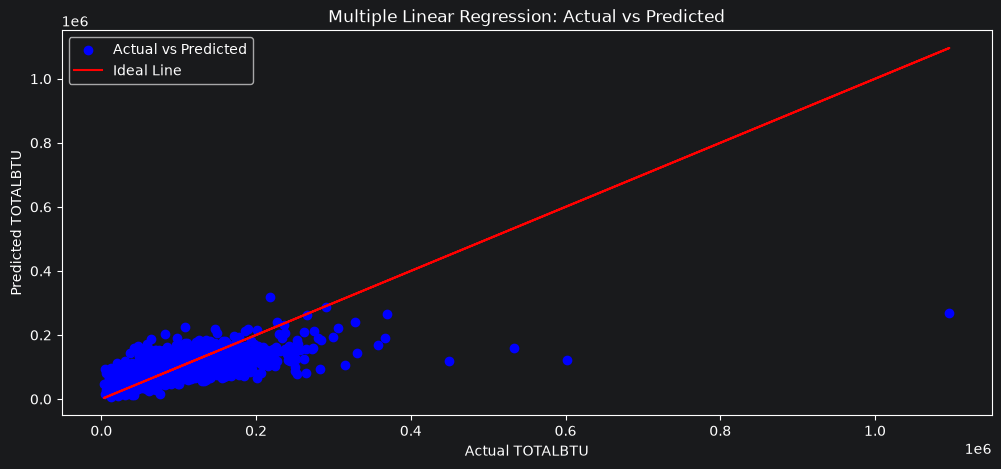

In [26]:
plt.figure(figsize=(12, 5))
plt.scatter(y_test, y_pred, color='blue', label='Actual vs Predicted')
plt.plot(y_test, y_test, color='red', label='Ideal Line')
plt.title('Multiple Linear Regression: Actual vs Predicted')
plt.xlabel('Actual TOTALBTU')
plt.ylabel('Predicted TOTALBTU')
plt.legend()
plt.show()

In [27]:
poly = PolynomialFeatures(degree=2)
x_train_trans = poly.fit_transform(x_train)
x_test_trans = poly.transform(x_test)

poly_model = LinearRegression()
poly_model.fit(x_train_trans, y_train)
y_pred_poly = poly_model.predict(x_test_trans)

In [28]:
df_results_poly = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred_poly})
df_results_poly.head(10)

,Actual,Predicted
1525,146243,88451.469622
8923,22946,49802.647555
3784,52187,76722.716154
2674,64752,51058.959732
9167,39202,31999.843217
2431,111493,133001.200358
4633,115019,119926.887852
2817,48734,72303.297228
6070,93504,76085.103222
4253,49807,51380.044019


In [29]:
MAE_poly = mean_absolute_error(y_test, y_pred_poly)
MSE_poly = mean_squared_error(y_test, y_pred_poly)
RMSE_poly = np.sqrt(MSE_poly)
r2_poly = r2_score(y_test, y_pred_poly)
print("Polynomial Regression MAE Value is ", MAE_poly)
print("Polynomial Regression MSE Value is ", MSE_poly)
print("Polynomial Regression RMSE Value is ", RMSE_poly)
print("Polynomial Regression R2 Value is ", r2_poly)

Polynomial Regression MAE Value is  26828.716105852192
Polynomial Regression MSE Value is  1781488655.2108545
Polynomial Regression RMSE Value is  42207.68478856492
Polynomial Regression R2 Value is  0.4591103517808536


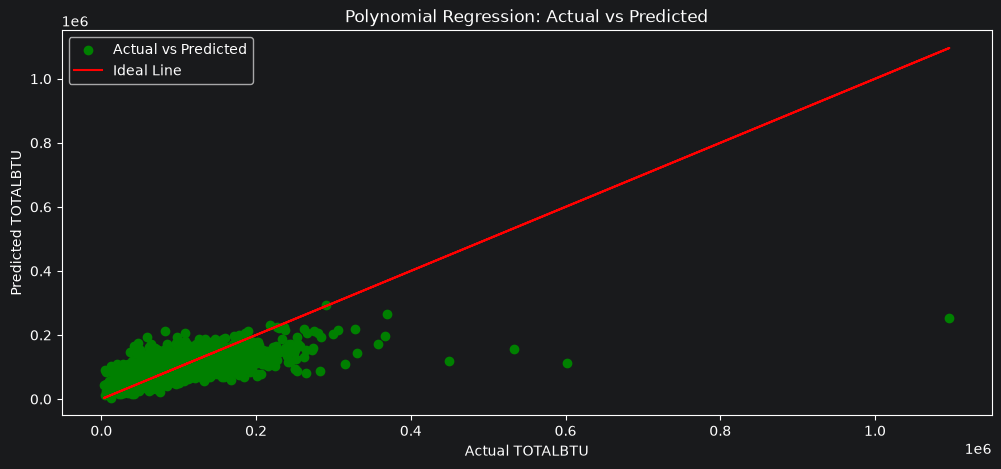

In [30]:
plt.figure(figsize=(12, 5))
plt.scatter(y_test, y_pred_poly, color='green', label='Actual vs Predicted')
plt.plot(y_test, y_test, color='red', label='Ideal Line')
plt.title('Polynomial Regression: Actual vs Predicted')
plt.xlabel('Actual TOTALBTU')
plt.ylabel('Predicted TOTALBTU')
plt.legend()
plt.show()

In [31]:
x = df[['TOTSQFT_EN', 'TOTROOMS', 'BEDROOMS', 'HDD65', 'CDD65', 'NHSLDMEM', 'MONEYPY', 'YEARMADERANGE']]
y = df['AIRCOND']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [32]:
lr = LogisticRegression()
lr.fit(x_train, y_train)
y_pred_lr = lr.predict(x_test)
y_prob_lr = lr.predict_proba(x_test)
print(y_prob_lr)

[[0.18222393 0.81777607]
 [0.13800667 0.86199333]
 [0.34569394 0.65430606]
 ...
 [0.18088555 0.81911445]
 [0.26550665 0.73449335]
 [0.17733026 0.82266974]]


E:\LPU\5th_Sem\INT\Codes\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [33]:
df_results_lr = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred_lr})
df_results_lr.head(10)

,Actual,Predicted
1525,1,1
8923,1,1
3784,1,1
2674,1,1
9167,0,1
2431,1,1
4633,1,1
2817,1,1
6070,1,1
4253,1,1


In [34]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)
print("Accuracy: ", accuracy_lr)
cm_lr = confusion_matrix(y_test, y_pred_lr)
print("Confusion Matrix:\n", cm_lr)
print("Classification Report:\n", classification_report(y_test, y_pred_lr))

Accuracy:  0.8218197135636057
Confusion Matrix:
 [[   7  422]
 [   1 1944]]
Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.02      0.03       429
           1       0.82      1.00      0.90      1945

    accuracy                           0.82      2374
   macro avg       0.85      0.51      0.47      2374
weighted avg       0.83      0.82      0.74      2374



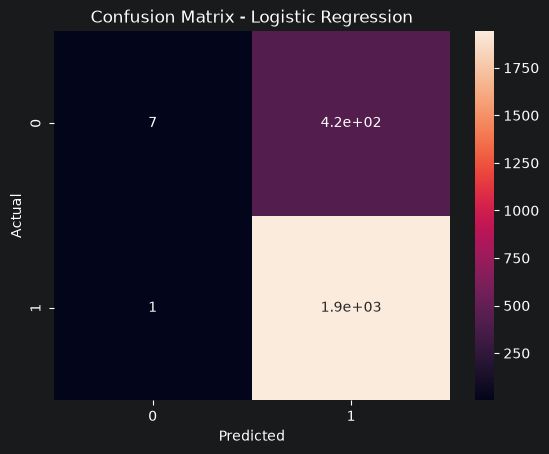

In [35]:
sns.heatmap(cm_lr, annot=True)
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [36]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [37]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train_scaled, y_train)
y_pred_knn = knn.predict(x_test_scaled)

In [38]:
df_results_knn = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred_knn})
df_results_knn.head(10)

,Actual,Predicted
1525,1,1
8923,1,1
3784,1,0
2674,1,1
9167,0,0
2431,1,1
4633,1,1
2817,1,1
6070,1,1
4253,1,0


In [39]:
accuracy_knn = accuracy_score(y_test, y_pred_knn)
print("Accuracy: ", accuracy_knn)
cm_knn = confusion_matrix(y_test, y_pred_knn)
print("Confusion Matrix:\n", cm_knn)
print("Classification Report:\n", classification_report(y_test, y_pred_knn))

Accuracy:  0.8243470935130581
Confusion Matrix:
 [[ 106  323]
 [  94 1851]]
Classification Report:
               precision    recall  f1-score   support

           0       0.53      0.25      0.34       429
           1       0.85      0.95      0.90      1945

    accuracy                           0.82      2374
   macro avg       0.69      0.60      0.62      2374
weighted avg       0.79      0.82      0.80      2374



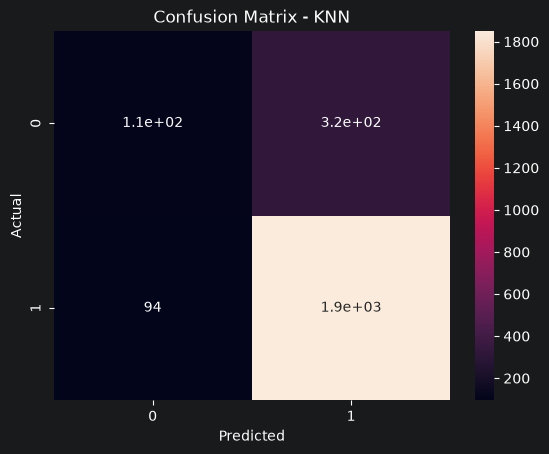

In [40]:
sns.heatmap(cm_knn, annot=True)
plt.title("Confusion Matrix - KNN")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [41]:
comparison_reg = pd.DataFrame({
    'Model': ['Multiple Linear Regression', 'Polynomial Regression'],
    'MAE': [MAE, MAE_poly],
    'MSE': [MSE, MSE_poly],
    'RMSE': [RMSE, RMSE_poly],
    'R2_Score': [r2, r2_poly]
})
comparison_reg

,Model,MAE,MSE,RMSE,R2_Score
0,Multiple Linear Regression,27190.892616,1.795941e+09,42378.542260,0.454722
1,Polynomial Regression,26828.716106,1.781489e+09,42207.684789,0.459110


In [42]:
comparison_clf = pd.DataFrame({
    'Model': ['Logistic Regression', 'KNN Classifier'],
    'Accuracy': [accuracy_lr, accuracy_knn]
})
comparison_clf

,Model,Accuracy
0,Logistic Regression,0.821820
1,KNN Classifier,0.824347
